# Isochrons 00. What is an isochron? The clock, the clock reading, and large kicks

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/isochrons/00_ML_isochrons-introduction.ipynb)

## 0. Introduction

> An oscillator that settles onto a stable limit cycle Γ has a clock: where it is on Γ. A
> state that is not on Γ also gets a clock reading, its asymptotic phase: wait until it has
> settled, and read off which point of Γ it is now keeping step with. The curves of equal
> asymptotic phase are the isochrons (Winfree 1974). Near Γ they are short straight lines,
> and their directions give the familiar infinitesimal phase response curve. Far from Γ they
> can bend, fold and pile up, and that is what decides how an oscillator responds to a large
> kick.

This notebook takes that paragraph apart, step by step, with the Morris–Lecar neuron:

| part | sentence | what is computed |
|---|---|---|
| **0a** | the clock and the clock reading | Γ and its period; phase θ = t/T; a state off Γ falling in step with one point of Γ; its clock reading (asymptotic phase); the equilibrium, which has none |
| **0b** | isochrons, straight near Γ | the phase map and its contour lines; states on one isochron moving together; near Γ, straight lines perpendicular to the adjoint; the infinitesimal PRC, checked with small kicks |
| **0c** | far from Γ, and large kicks | isochrons bending, folding around the equilibrium and piling up; where a large kick lands; PRCs for growing kicks |

**Another oscillator:** everything is computed from the `OSC` cell below. Replace it (a
FitzHugh–Nagumo and a van der Pol version are given) and run all cells: every section works
the same way for the new oscillator.

The sliders and *Compute* buttons need a running kernel. Every number is computed by XPPAUT
8.2 through pyauto-xpp.

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp tqdm --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.3.0

## The oscillator (the only cell to change for another oscillator)

Everything below reads the model from `OSC`: two variables, their right-hand sides, the
parameters and a starting state that goes to the limit cycle. The phase 0 of the clock is
the maximum of the **first** variable, a "spike" is the first variable crossing the middle of
its range on Γ upward, and kicks are in the first variable. To study another oscillator,
replace `OSC` (FitzHugh–Nagumo and van der Pol are given, commented out).

The default is the Morris–Lecar neuron, Rinzel & Ermentrout's parameters with I = 100:

$$ C\dot V = I - g_L(V-V_L) - g_{Ca}\, m_\infty(V)(V-V_{Ca}) - g_K\, w\,(V-V_K), \qquad
   \dot w = \phi\,\frac{w_\infty(V)-w}{\tau_w(V)} $$

(V1..V4 of the model are called va1..va4: XPP names the copies of v in a network V0, V1, …,
so a parameter may not be a variable name followed by digits.)

In [2]:
OSC = dict(
    name="morris_lecar",
    variables=("v", "w"),                       # (first, second); phase 0 = max of the first
    units=("mV", ""),                           # for axis labels
    functions=[("minf(v)", "0.5*(1+tanh((v-va1)/va2))"), ("winf(v)", "0.5*(1+tanh((v-va3)/va4))"),
               ("tauw(v)", "1/cosh((v-va3)/(2*va4))")],
    rhs={"v": "(i-gl*(v-vl)-gca*minf(v)*(v-vca)-gk*w*(v-vk))/c",
         "w": "phi*(winf(v)-w)/tauw(v)"},
    parameters=dict(i=100, c=20, gl=2, vl=-60, gca=4.4, vca=120, gk=8, vk=-84,
                    va1=-1.2, va2=18, va3=2, va4=30, phi=0.04),
    start=dict(v=-30, w=0.1),                   # a state that goes to the limit cycle
    dt=0.05,                                    # integration step
    window=(-70.0, 50.0, 0.0, 0.65),            # optional: (xmin, xmax, ymin, ymax); None = from Γ
)

# FitzHugh-Nagumo:
# OSC = dict(name="fitzhugh_nagumo", variables=("v", "w"), units=("", ""), functions=[],
#            rhs={"v": "v-v^3/3-w+i", "w": "eps*(v+a-b*w)"},
#            parameters=dict(i=0.5, a=0.7, b=0.8, eps=0.08), start=dict(v=-1, w=1), dt=0.01,
#            window=None)
# van der Pol (mu = 2):
# OSC = dict(name="van_der_pol", variables=("x", "y"), units=("", ""), functions=[],
#            rhs={"x": "y", "y": "mu*(1-x^2)*y-x"}, parameters=dict(mu=2),
#            start=dict(x=0.5, y=0), dt=0.005, window=None)

## Setup (general: works for any `OSC`)

Builds the model in XPPAUT (its `.ode` file is printed), finds Γ, the period T (XPP:
*Initialconds > Go*, then *Initialconds > Periodic*), phase 0 γ0 at the maximum of the first
variable, the spike threshold, the equilibrium inside Γ, and a network of copies of the model
to compute many clock readings in one XPP run.

In [3]:
import hashlib
import json
import os
import re
import tempfile
import urllib.request
from pathlib import Path

import ipywidgets as W
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from pyxpp.builder import ModelBuilder
from tqdm.auto import tqdm

WORK, HERE = Path(tempfile.mkdtemp()), Path.cwd()
X, Y = OSC["variables"]
UX, UY = OSC["units"]
LX, LY = (f"{X} ({UX})" if UX else X), (f"{Y} ({UY})" if UY else Y)
DT, NC = OSC["dt"], 200
for p in OSC["parameters"]:                     # a parameter like v1 would clash with the copies of v
    if re.fullmatch(rf"({X}|{Y})\d+", p, flags=re.I):
        raise ValueError(f"rename parameter {p}: XPP uses that name for a copy of a variable")

mb = ModelBuilder(OSC["name"])
for sig, expr in OSC["functions"]:
    mb.function(sig, expr)
mb = (mb.ode(X, OSC["rhs"][X]).ode(Y, OSC["rhs"][Y]).parameter(**OSC["parameters"])
      .initial(**OSC["start"]).option(total=20000 * DT, dt=DT, meth="rk4", bound=1e6, maxstor=400000))
print(mb.render())
m = mb.load(WORK / f"{OSC['name']}.ode")

# onto the cycle (long enough to forget the start), then its period
m.run(keep=False, total=20000 * DT)
s = m.last_state()
m.set(**{X: s[X.upper()], Y: s[Y.upper()]})
m.run()
m.buttons.xi_vs_t(X)
m.buttons.initialconds.periodic()              # sets total = T
T = m.numerics["total"]
c0 = m.run(keep=False, total=T, dt=T / 20000)
k0 = int(np.argmax(c0[X]))
gamma0 = np.array([c0[X][k0], c0[Y][k0]])       # phase 0: maximum of the first variable
m.set(**{X: gamma0[0], Y: gamma0[1]})
c0 = m.run(keep=False, total=T, dt=T / 20000)
CX, CY, CT = np.asarray(c0[X], float), np.asarray(c0[Y], float), np.asarray(c0.t, float)
THR = 0.5 * (CX.min() + CX.max())               # spike: first variable crosses this upward
SX, SY = CX.max() - CX.min(), CY.max() - CY.min()   # scales of Γ, for distances
if OSC.get("window"):
    WIN = tuple(OSC["window"])
else:
    WIN = (CX.min() - 0.4 * SX, CX.max() + 0.4 * SX, CY.min() - 0.4 * SY, CY.max() + 0.4 * SY)
try:
    eq = m.equilibrium({X: float(CX.mean()), Y: float(CY.mean())})
    xstar = np.array([eq.x[X.upper()], eq.x[Y.upper()]])
except Exception:
    xstar = None                                 # no equilibrium found inside Γ


def gamma(theta):
    """the point of Γ whose clock reads theta"""
    s = (theta % 1) * T
    return np.array([np.interp(s, CT, CX), np.interp(s, CT, CY)])


def upcross(t, x, thr=None):
    """times where x crosses the threshold upward: the spikes"""
    thr = THR if thr is None else thr
    i = np.nonzero((x[:-1] < thr) & (x[1:] >= thr))[0]
    return t[i] + (thr - x[i]) / (x[i + 1] - x[i]) * (t[i + 1] - t[i])


m.set(**{X: gamma0[0], Y: gamma0[1]})
r = m.run(keep=False, total=3 * T, dt=DT)
t_c0 = upcross(np.asarray(r.t, float), np.asarray(r[X], float))[0]   # the cycle's spike after gamma0

# N uncoupled copies of the model in one XPP model (a network): one run, N states
nb = ModelBuilder(OSC["name"] + "_network")
for sig, expr in OSC["functions"]:
    nb.function(sig, expr)
idx = {k: re.sub(rf"\b{Y}\b", f"{Y}[j]", re.sub(rf"\b{X}\b", f"{X}[j]", e)) for k, e in OSC["rhs"].items()}
net = (nb.ode(f"{X}[0..{NC - 1}]", idx[X]).ode(f"{Y}[0..{NC - 1}]", idx[Y])
       .parameter(**OSC["parameters"]).option(dt=DT, meth="rk4", bound=1e6, maxstor=400000)
       .load(WORK / f"{OSC['name']}_network.ode"))


def clock_reading(points, periods=8):
    """the asymptotic phase of each state: theta = ((t_c0 - t_s)/T) mod 1, from a spike t_s
    after the state has settled on Γ (NaN if it has not settled after `periods` periods)"""
    pts = np.atleast_2d(np.asarray(points, float))
    out = np.full(len(pts), np.nan)
    for s0 in range(0, len(pts), NC):
        chunk = pts[s0:s0 + NC]
        ic = {}
        for j in range(NC):
            p = chunk[j] if j < len(chunk) else chunk[0]
            ic[f"{X}{j}"], ic[f"{Y}{j}"] = p[0], p[1]
        net.ics.update(ic)
        A = net.run(total=periods * T, trans=(periods - 2.5) * T).array
        t, XX = A[:, 0], A[:, 1:1 + len(chunk)]
        for c in range(len(chunk)):
            s = upcross(t, XX[:, c])
            if len(s) >= 2 and abs(s[-1] - s[-2] - T) < 1e-3 * T:
                out[s0 + c] = ((t_c0 - s[-1]) / T) % 1
    return out


def trajectory(x, total):
    m.set(**{X: x[0], Y: x[1]})
    tr = m.run(keep=False, total=total, dt=DT)
    return np.asarray(tr.t, float), np.asarray(tr[X], float), np.asarray(tr[Y], float)


def dist(a, b):
    """distance between states, each variable scaled by the size of Γ"""
    return np.hypot((np.asarray(a)[..., 0] - np.asarray(b)[..., 0]) / SX,
                    (np.asarray(a)[..., 1] - np.asarray(b)[..., 1]) / SY)


def draw_cycle(ax, marks=False):
    ax.plot(CX, CY, color="k", lw=2.5)
    if xstar is not None:
        ax.plot(*xstar, "x", color="k", ms=9)
    if marks:
        for th in np.arange(0, 1, 0.05):
            ax.plot(*gamma(th), "o", color=plt.cm.hsv(th), ms=5)
    ax.set(xlim=WIN[:2], ylim=WIN[2:], xlabel=LX, ylabel=LY)


INTERACTIVE = not os.environ.get("ISOCHRON_HEADLESS")   # False only when built without a browser
print(f"{OSC['name']}: period T = {T:.4f}; phase 0 at gamma0 = ({gamma0[0]:.4f}, {gamma0[1]:.4f}); "
      f"spike threshold {X} = {THR:.4f}" +
      (f"; equilibrium x* = ({xstar[0]:.4f}, {xstar[1]:.4f})" if xstar is not None else ""))

minf(v)=0.5*(1+tanh((v-va1)/va2))
winf(v)=0.5*(1+tanh((v-va3)/va4))
tauw(v)=1/cosh((v-va3)/(2*va4))
v'=(i-gl*(v-vl)-gca*minf(v)*(v-vca)-gk*w*(v-vk))/c
w'=phi*(winf(v)-w)/tauw(v)
par i=100,c=20,gl=2,vl=-60,gca=4.4,vca=120,gk=8,vk=-84,va1=-1.2,va2=18,va3=2,va4=30,phi=0.04
init v=-30,w=0.1
@ total=1000.0,dt=0.05,meth=rungekutta,bound=1000000.0,maxstor=400000
done



morris_lecar: period T = 85.2906; phase 0 at gamma0 = (33.3258, 0.3054); spike threshold v = -8.5051; equilibrium x* = (-23.0918, 0.1581)


### The phase map: the clock reading of every state on a grid

Computed once with `clock_reading` (a few minutes) and stored in `data/` under a name that
depends on the oscillator, so changing `OSC` computes a new map. For the default Morris–Lecar
model it is downloaded in Colab if published.

In [4]:
key = hashlib.sha1(json.dumps(OSC, sort_keys=True, default=str).encode()).hexdigest()[:8]
MAPFILE = HERE / "data" / f"{OSC['name']}_phase_map_{key}.npz"
RAWMAP = f"https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/data/{MAPFILE.name}"
if not MAPFILE.exists():
    MAPFILE.parent.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(RAWMAP, MAPFILE)
    except Exception:
        VG, WG = np.meshgrid(np.linspace(WIN[0], WIN[1], 121), np.linspace(WIN[2], WIN[3], 91))
        g = np.c_[VG.ravel(), WG.ravel()]
        TH = np.concatenate([clock_reading(g[s:s + 1000])
                             for s in tqdm(range(0, len(g), 1000), desc="phase map")]).reshape(VG.shape)
        np.savez(MAPFILE, V=VG, W=WG, TH=TH)
d = np.load(MAPFILE)
VG, WG, TH = d["V"], d["W"], d["TH"]          # grid of the first and second variable, clock reading


def no_wrap(F):
    """hide grid points next to a jump > 0.5 (where the reading wraps from 1 to 0)"""
    bad = np.zeros(F.shape, bool)
    dx, dy = np.abs(np.diff(F, axis=1)) > 0.5, np.abs(np.diff(F, axis=0)) > 0.5
    bad[:, :-1] |= dx; bad[:, 1:] |= dx; bad[:-1, :] |= dy; bad[1:, :] |= dy
    return np.ma.masked_where(bad | np.isnan(F), F)


def isochron(ax, level, **kw):
    """the isochron of clock reading `level`: a contour line of the phase map"""
    level = level if level > 0 else 1e-9
    if 0.25 <= level <= 0.75:
        return ax.contour(VG, WG, no_wrap(TH), [level], **kw)
    return ax.contour(VG, WG, no_wrap((TH + 0.5) % 1), [(level + 0.5) % 1], **kw)


def phase_background(ax):
    ax.pcolormesh(VG, WG, TH, cmap="hsv", shading="auto", vmin=0, vmax=1, alpha=0.45)

### The adjoint along Γ

XPP: from γ0, *Numerics > Averaging > New adj*. Z(t) is the gradient of the clock reading at
γ(t/T), normalised so that Z·F = 1: a small displacement Δx changes the clock reading by
about Z·Δx / T.

In [5]:
m.set(**{X: gamma0[0], Y: gamma0[1]})
m.run(keep=False, total=T, dt=T / 20000)
A_ = m.buttons.numerics.averaging
A_.parameters(4000)
A_.new_adj()
adj = m.data
ZT, ZX, ZY = np.asarray(adj.t, float), np.asarray(adj[X], float), np.asarray(adj[Y], float)


def Z(theta):
    return np.array([np.interp(theta * T, ZT, ZX), np.interp(theta * T, ZT, ZY)])


def isochron_step(theta):
    """one scaled unit along the straight isochron at gamma(theta): perpendicular to Z, with
    each variable scaled by the size of Γ (SX, SY)"""
    z = Z(theta)
    zs = np.array([z[0] * SX, z[1] * SY])            # the gradient in scaled coordinates
    ts = np.array([zs[1], -zs[0]]) / np.hypot(*zs)   # unit tangent, scaled coordinates
    return np.array([SX * ts[0], SY * ts[1]])

## 0a. The clock, and the clock reading of any state

> An oscillator that settles onto a stable limit cycle Γ has a **clock**: where it is on Γ.
> A state that is not on Γ also gets a **clock reading**, its asymptotic phase: wait until it
> has settled, and read off which point of Γ it is now keeping step with.

### 0a.1 The limit cycle Γ and its period

Start anywhere; after a while the trajectory repeats itself: it has reached the limit cycle
Γ. The time it takes to go once around is the period T.

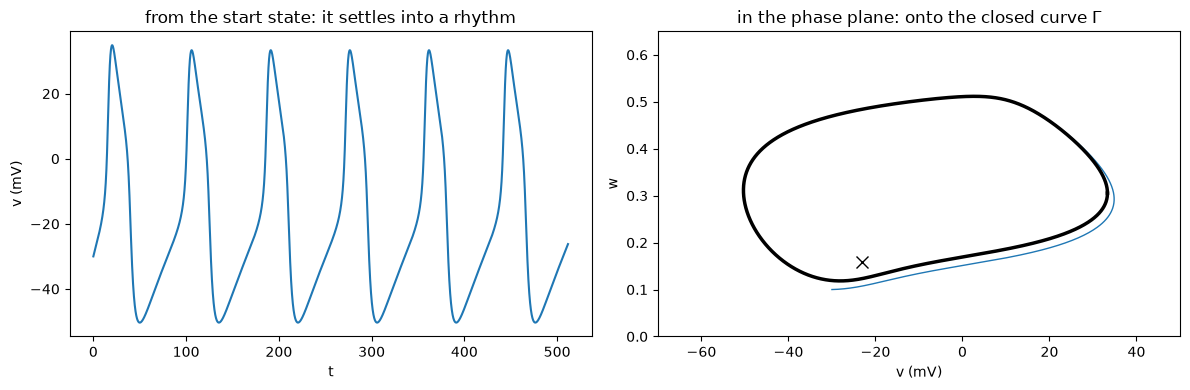

period T = 85.2906 (from XPP's Initialconds > Periodic)


In [6]:
start = np.array([OSC["start"][X], OSC["start"][Y]])
t, x, y = trajectory(start, 6 * T)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(t, x, color="C0"); a1.set(xlabel="t", ylabel=LX, title="from the start state: it settles into a rhythm")
a2.plot(x, y, color="C0", lw=1); draw_cycle(a2); a2.set_title("in the phase plane: onto the closed curve Γ")
plt.tight_layout(); plt.show()
print(f"period T = {T:.4f} (from XPP's Initialconds > Periodic)")

### 0a.2 The clock on Γ

Pick one point of Γ and call its phase 0: here γ0, the maximum of the first variable. The
point reached from γ0 after time t has phase θ = t/T. The clock runs at a steady rate around
Γ, so equal steps in θ are equal steps in **time**, not in distance: the marks below (every
0.05) are crowded where Γ is slow and sparse where it is fast.

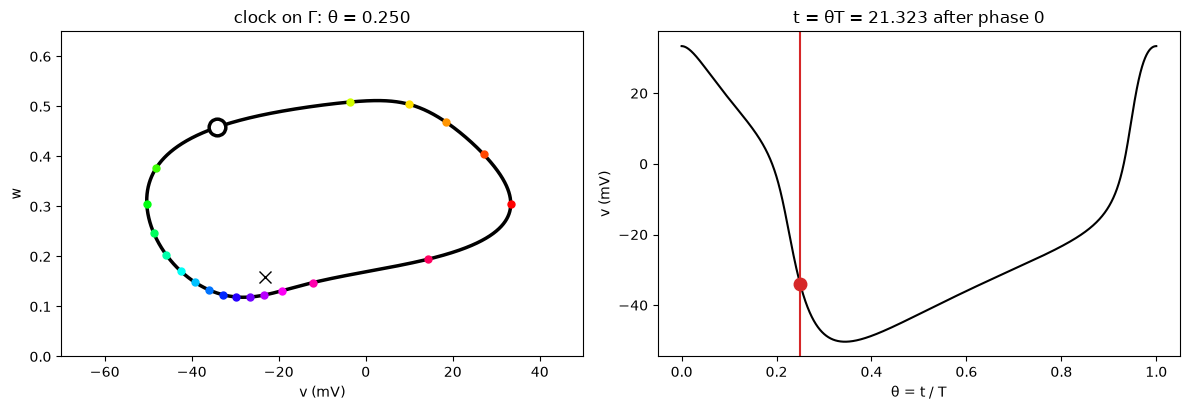

θ = 0.250: the point (v, w) = (-34.11, 0.4584) of Γ


In [7]:
def show_clock(theta):
    g = gamma(theta)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
    draw_cycle(a1, marks=True)
    a1.plot(*g, "o", color="k", ms=12, mfc="white", mew=2.5)
    a1.set_title(f"clock on Γ: θ = {theta:.3f}")
    a2.plot(CT / T, CX, color="k"); a2.axvline(theta, color="C3"); a2.plot(theta, g[0], "o", color="C3", ms=9)
    a2.set(xlabel="θ = t / T", ylabel=LX, title=f"t = θT = {theta * T:.3f} after phase 0")
    plt.tight_layout(); plt.show()
    print(f"θ = {theta:.3f}: the point ({X}, {Y}) = ({g[0]:.4g}, {g[1]:.4g}) of Γ")


show_clock(0.25)

**Try it:** move the slider (it needs a running kernel).

In [8]:
a_theta = W.FloatSlider(value=0.25, min=0, max=0.999, step=0.005, description="θ",
                     continuous_update=False, readout_format=".3f")
a_out1 = W.Output()
def _a_clock(*_):
    with a_out1:
        a_out1.clear_output(wait=True); show_clock(a_theta.value)
a_theta.observe(_a_clock, "value")
display(W.VBox([a_theta, a_out1]))
if INTERACTIVE:
    _a_clock()

### 0a.3 A state off Γ falls in step with one point of Γ

Take a state x0 inside Γ. Its trajectory goes to Γ, but where on Γ does it end up? Run it
next to three points of Γ: after the transient it moves exactly together with **one** of
them.

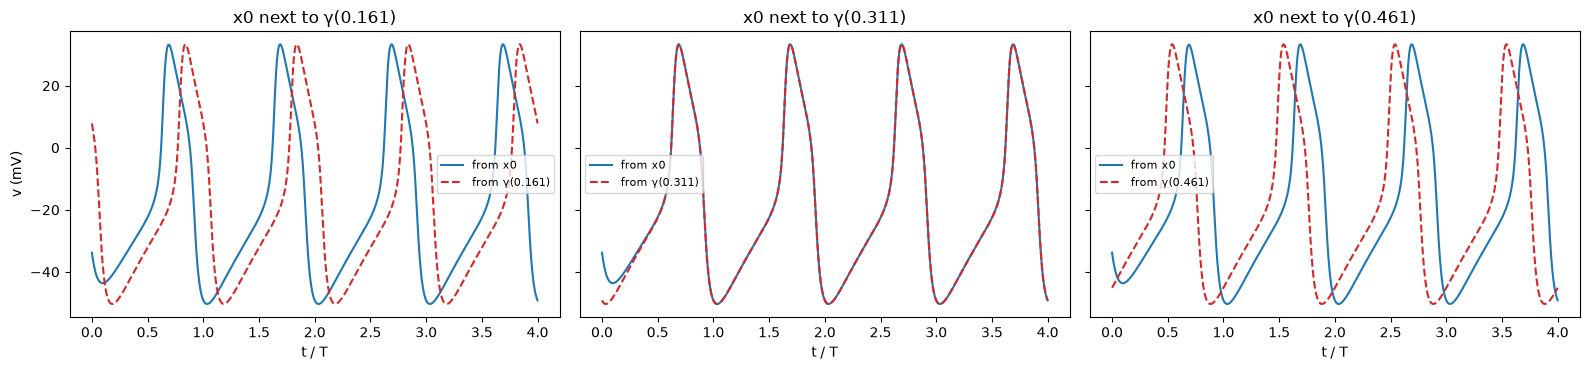

x0 = (-33.81, 0.3184) keeps step with γ(0.311): the middle panel


In [9]:
centre = np.array([CX.mean(), CY.mean()])
x0 = centre + 0.5 * (gamma(0.3) - centre)           # a state inside Γ
th0 = clock_reading(x0)[0]
t, x, y = trajectory(x0, 4 * T)
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, th in zip(axs, (th0 - 0.15, th0, th0 + 0.15)):
    tg, xg, yg = trajectory(gamma(th), 4 * T)
    ax.plot(t / T, x, color="C0", label="from x0")
    ax.plot(tg / T, xg, "--", color="C3", label=f"from γ({th % 1:.3f})")
    ax.set(xlabel="t / T", title=f"x0 next to γ({th % 1:.3f})")
    ax.legend(fontsize=8)
axs[0].set_ylabel(LX)
plt.tight_layout(); plt.show()
print(f"x0 = ({x0[0]:.4g}, {x0[1]:.4g}) keeps step with γ({th0:.3f}): the middle panel")

That θ0 is the **clock reading** of x0.

### 0a.4 The clock reading (asymptotic phase), and how it is computed

Formally (Winfree 1974; Guckenheimer 1975):

$$ \lim_{t\to\infty} \big\| \Phi(t, x_0) - \Phi(t + \theta(x_0)\,T,\ \gamma_0) \big\| = 0 $$

In practice: let x0 settle, note the time t_s of one of its spikes (the first variable
crossing the threshold upward), and compare it with the cycle's spike at t_c0 after γ0. If
x0 fires earlier by Δ, its clock is ahead by Δ/T:

$$ \theta(x_0) = \frac{t_{c0} - t_s}{T} \mod 1 $$

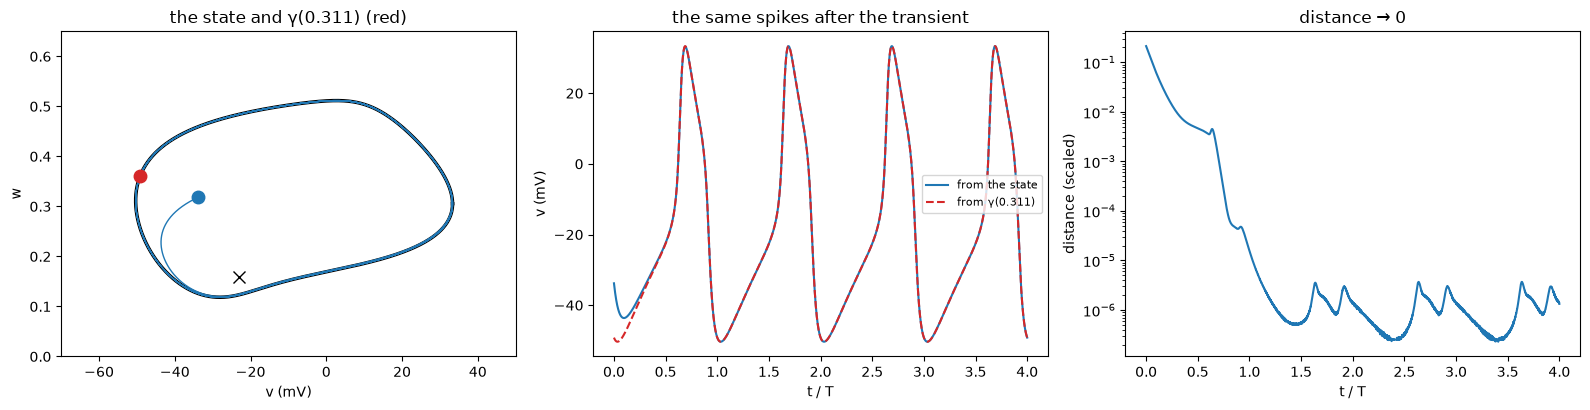

CLOCK READING θ = 0.3107: the state (-33.81, 0.3184) ends up keeping step with γ(0.3107) = (-49.18, 0.3604).


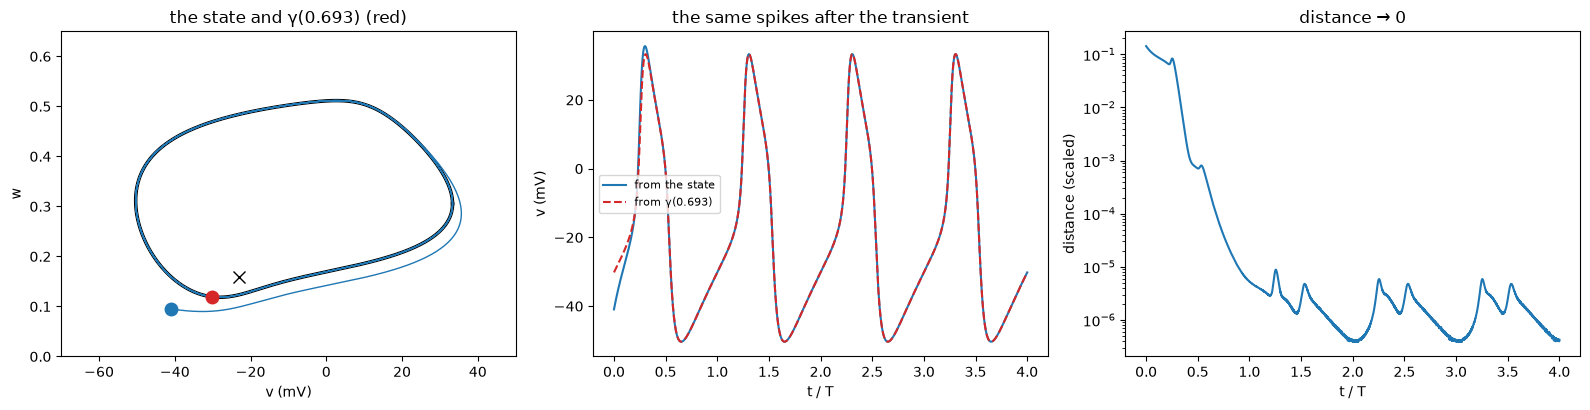

CLOCK READING θ = 0.6932: the state (-40.94, 0.09498) ends up keeping step with γ(0.6932) = (-30.18, 0.1193).


In [10]:
def show_reading(x_, y_):
    xs = np.array([x_, y_])
    th = clock_reading(xs)[0]
    if np.isnan(th):
        print("this state has not settled after 8 periods: it starts too close to x*, the point "
              "with no clock reading (section 5)")
        return
    g = gamma(th)
    t, x, y = trajectory(xs, 4 * T)
    tg, xg, yg = trajectory(g, 4 * T)
    dd = dist(np.c_[x, y], np.c_[xg, yg])
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 4.2))
    draw_cycle(a1); a1.plot(x, y, color="C0", lw=1)
    a1.plot(*xs, "o", color="C0", ms=9); a1.plot(*g, "o", color="C3", ms=9)
    a1.set_title(f"the state and γ({th:.3f}) (red)")
    a2.plot(t / T, x, color="C0", label="from the state"); a2.plot(tg / T, xg, "--", color="C3", label=f"from γ({th:.3f})")
    a2.set(xlabel="t / T", ylabel=LX, title="the same spikes after the transient"); a2.legend(fontsize=8)
    a3.semilogy(t / T, dd + 1e-12); a3.set(xlabel="t / T", ylabel="distance (scaled)", title="distance → 0")
    plt.tight_layout(); plt.show()
    print(f"CLOCK READING θ = {th:.4f}: the state ({x_:.4g}, {y_:.4g}) ends up keeping step with "
          f"γ({th:.4f}) = ({g[0]:.4g}, {g[1]:.4g}).")


show_reading(*x0)
outside = gamma(0.6) + 0.3 * (gamma(0.6) - centre)      # a state outside Γ
show_reading(*outside)

**Try it:** choose a state and press *Compute* (a few seconds: XPP integrates it for 8
periods).

In [11]:
a_x = W.FloatSlider(value=float(x0[0]), min=WIN[0], max=WIN[1], step=(WIN[1] - WIN[0]) / 240,
                    description=X, continuous_update=False, readout_format=".3g")
a_y = W.FloatSlider(value=float(x0[1]), min=WIN[2], max=WIN[3], step=(WIN[3] - WIN[2]) / 240,
                    description=Y, continuous_update=False, readout_format=".3g")
a_go = W.Button(description="Compute", button_style="primary", icon="play")
a_out2 = W.Output()
def _a_read(*_):
    with a_out2:
        a_out2.clear_output(wait=True); show_reading(a_x.value, a_y.value)
a_go.on_click(_a_read)
display(W.VBox([W.HBox([a_x, a_y, a_go]), a_out2]))

### 0a.5 A state with no clock reading

An unstable equilibrium x* inside Γ never moves, so it never reaches Γ and has no clock
reading. States close to it leave it slowly, so they need more periods to settle, and their
clock readings jump around: right next to x*, every phase can be found. The set of states
with no clock reading is the **phaseless set**.

In [12]:
if xstar is None:
    print("no equilibrium found inside Γ for this oscillator")
else:
    for f in (1e-2, 1e-4, 1e-6, 1e-8):
        xs = xstar + np.array([f * SX, 0.0])
        print(f"x* + {f:g}·(width of Γ):  clock reading after 8 periods = {clock_reading(xs, periods=8)[0]:.4f},"
              f"  after 30 periods = {clock_reading(xs, periods=30)[0]:.4f}")

x* + 0.01·(width of Γ):  clock reading after 8 periods = 0.8013,  after 30 periods = 0.8013


x* + 0.0001·(width of Γ):  clock reading after 8 periods = 0.8222,  after 30 periods = 0.8222


x* + 1e-06·(width of Γ):  clock reading after 8 periods = nan,  after 30 periods = 0.8203


x* + 1e-08·(width of Γ):  clock reading after 8 periods = nan,  after 30 periods = 0.7480


NaN means "not settled yet": the closer to x*, the more periods it takes, and x* itself never
settles. Note also how much the reading changes between neighbouring starts near x*.

### 0a: summary

* Γ has a **clock**: θ = t/T, measured from phase 0 at γ0.
* Any other state gets a **clock reading** (its asymptotic phase): the phase of the point of
  Γ it ends up keeping step with, computed from spike times after it has settled.
* An unstable equilibrium has none: the **phaseless set**.

**Next, part 0b:** all states with the same clock reading form a curve, an **isochron**; near Γ
these curves are straight lines that give the infinitesimal phase response curve.

## 0b. Curves of equal clock reading: the isochrons, and why they are straight near Γ

> The curves of equal asymptotic phase are the **isochrons** (Winfree 1974). **Near Γ** they
> are short straight lines, and their directions give the familiar **infinitesimal phase
> response curve**.

### 0b.1–2 The phase map and its contour lines: isochrons

Colour = clock reading of each state (from 00a). The **isochron** I(γ) of a point γ of Γ is
the set of all states with γ's clock reading: a contour line of the phase map. Each one
crosses Γ once, at the point with that phase (white dots).

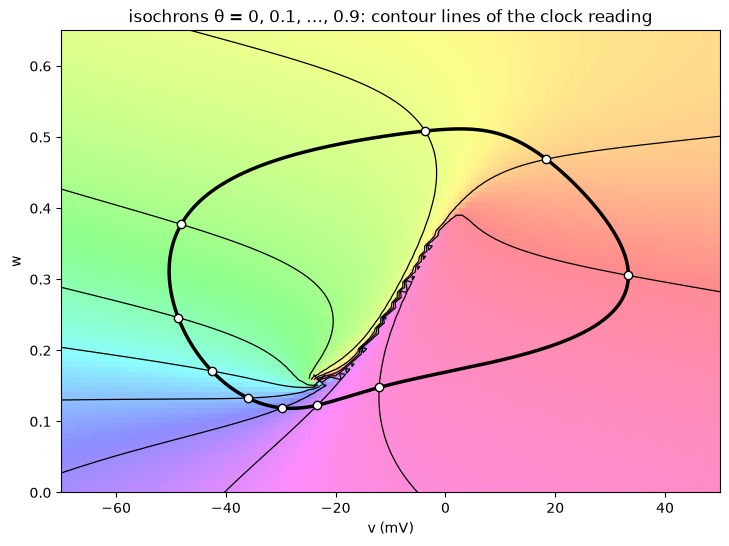

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 6))
phase_background(ax)
for lv in np.arange(0, 1, 0.1):
    isochron(ax, lv, colors="k", linewidths=0.9)
draw_cycle(ax)
for lv in np.arange(0, 1, 0.1):
    ax.plot(*gamma(lv), "o", color="k", mfc="white", ms=6)
ax.set_title("isochrons θ = 0, 0.1, …, 0.9: contour lines of the clock reading")
plt.show()

### 0b.3 States on one isochron move together

Take many states on the isochron θ = 0.2 and let them all move. At every moment they lie on
one isochron again (of phase 0.2 + t/T: the flow carries isochrons to isochrons), and they
all shrink onto the one point of Γ whose clock reads the same.

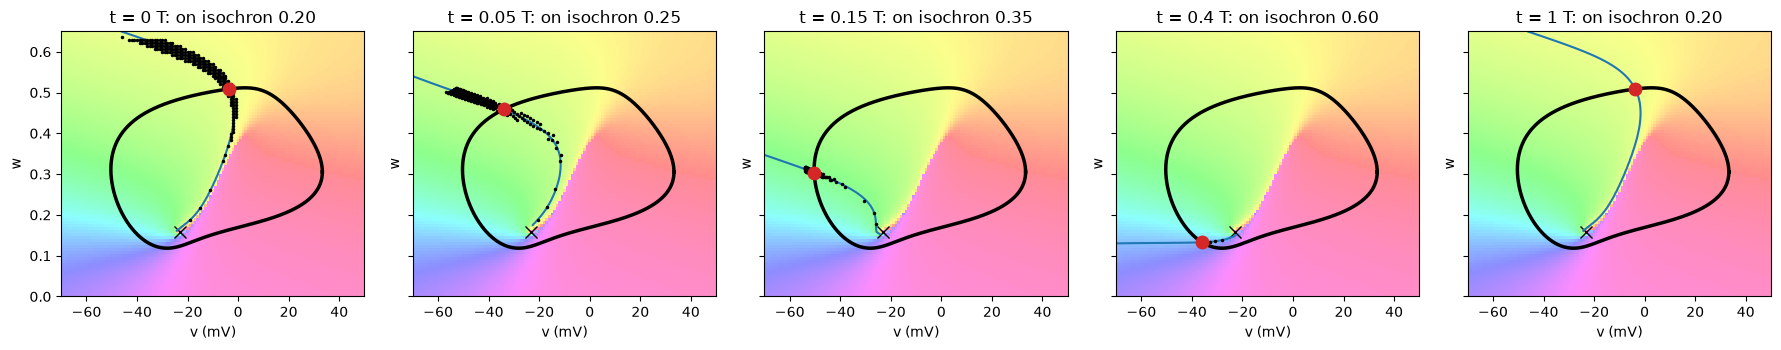

In [14]:
grid = np.c_[VG.ravel(), WG.ravel()]
sel = grid[np.abs(TH.ravel() - 0.2) < 0.004][:NC]
ic = {}
for j in range(NC):
    p = sel[j] if j < len(sel) else sel[0]
    ic[f"{X}{j}"], ic[f"{Y}{j}"] = p[0], p[1]
net.ics.update(ic)
A = net.run(total=1.2 * T, trans=0).array
fig, axs = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for ax, tt in zip(axs, (0, 0.05, 0.15, 0.4, 1.0)):
    k = int(np.argmin(np.abs(A[:, 0] - tt * T)))
    phase_background(ax); draw_cycle(ax)
    isochron(ax, (0.2 + tt) % 1, colors="C0", linewidths=1.5)
    ax.plot(A[k, 1:1 + len(sel)], A[k, 1 + NC:1 + NC + len(sel)], ".", color="k", ms=3)
    ax.plot(*gamma(0.2 + tt), "o", color="C3", ms=9)
    ax.set_title(f"t = {tt:g} T: on isochron {(0.2 + tt) % 1:.2f}")
plt.tight_layout(); plt.show()

### 0b.4 Near Γ an isochron is a straight line

Zoom in on Γ at γ(θ): the isochron (red) is a straight line through γ(θ), perpendicular to
the adjoint Z(θ), the gradient of the clock reading. How far is that true? Measure the clock
reading of points on the straight line at growing distance (each variable scaled by the size
of Γ): it stays θ, to the accuracy of the computation, close to Γ, and drifts further out,
where the isochron starts to bend (00c).

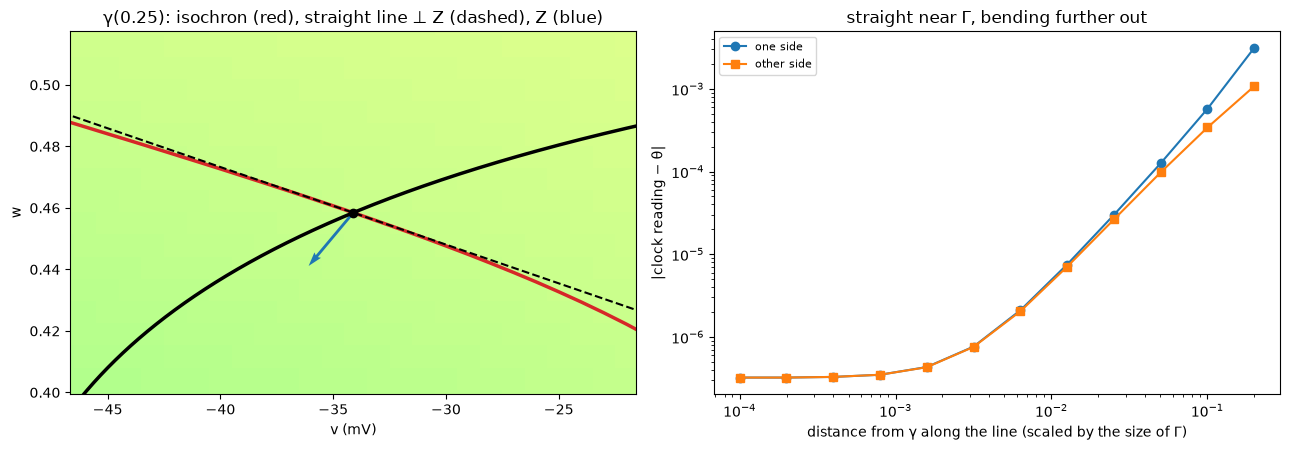

In [15]:
def show_near(theta):
    g, step = gamma(theta), isochron_step(theta)
    dd = np.r_[-np.geomspace(0.2, 1e-4, 12), np.geomspace(1e-4, 0.2, 12)]
    pts = np.array([g + d * step for d in dd])
    dev = (clock_reading(pts) - theta + 0.5) % 1 - 0.5
    z = Z(theta)
    zs = np.array([z[0] * SX, z[1] * SY]); zs /= np.hypot(*zs)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
    phase_background(a1)
    isochron(a1, theta, colors="C3", linewidths=2.5)
    draw_cycle(a1)
    a1.plot(pts[:, 0], pts[:, 1], "k--", lw=1.5)
    a1.quiver(*g, 0.05 * SX * zs[0], 0.05 * SY * zs[1], color="C0", angles="xy", scale_units="xy",
              scale=1, width=0.005)
    a1.plot(*g, "ko")
    a1.set(xlim=(g[0] - 0.15 * SX, g[0] + 0.15 * SX), ylim=(g[1] - 0.15 * SY, g[1] + 0.15 * SY),
           title=f"γ({theta:.2f}): isochron (red), straight line ⊥ Z (dashed), Z (blue)")
    a2.loglog(np.abs(dd[dd < 0]), np.abs(dev[dd < 0]) + 1e-8, "o-", label="one side")
    a2.loglog(dd[dd > 0], np.abs(dev[dd > 0]) + 1e-8, "s-", label="other side")
    a2.set(xlabel="distance from γ along the line (scaled by the size of Γ)",
           ylabel="|clock reading − θ|", title="straight near Γ, bending further out")
    a2.legend(fontsize=8)
    plt.tight_layout(); plt.show()


show_near(0.25)

**Try it:** another phase (press *Compute*).

In [16]:
b_theta = W.FloatSlider(value=0.6, min=0, max=0.999, step=0.01, description="θ", continuous_update=False)
b_go = W.Button(description="Compute", button_style="primary", icon="play")
b_out = W.Output()
def _b_near(*_):
    with b_out:
        b_out.clear_output(wait=True); show_near(b_theta.value)
b_go.on_click(_b_near)
display(W.VBox([W.HBox([b_theta, b_go]), b_out]))

### 0b.5 The direction gives the infinitesimal phase response curve

A small kick Δ in the first variable at phase θ moves the state off Γ by (Δ, 0). Its clock
reading changes by about Z_x(θ)·Δ / T: the component of the kick across the isochrons. The
curve Z_x(θ)/T is the **infinitesimal phase response curve (PRC)**. Check it against small
kicks computed directly with the clock reading:

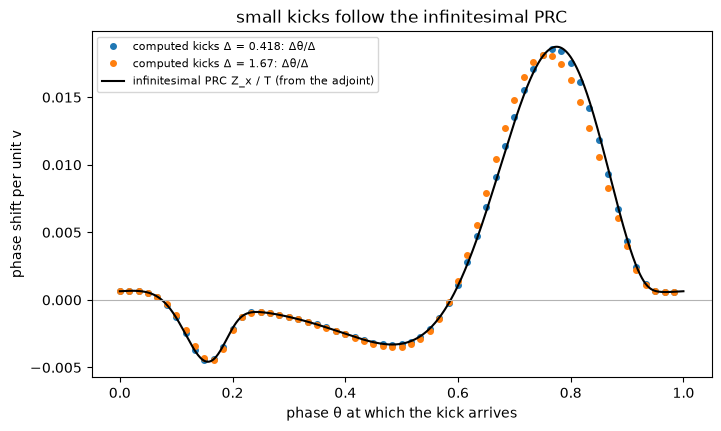

In [17]:
ths = np.linspace(0, 1, 60, endpoint=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
for f in (0.005, 0.02):
    dk = f * SX
    new = clock_reading([gamma(t) + np.array([dk, 0.0]) for t in ths])
    ax.plot(ths, ((new - ths + 0.5) % 1 - 0.5) / dk, "o", ms=4, label=f"computed kicks Δ = {dk:.3g}: Δθ/Δ")
ax.plot(ZT / T, ZX / T, "k-", label="infinitesimal PRC Z_x / T (from the adjoint)")
ax.axhline(0, color="0.7", lw=0.8)
ax.set(xlabel="phase θ at which the kick arrives", ylabel=f"phase shift per unit {X}",
       title="small kicks follow the infinitesimal PRC")
ax.legend(fontsize=8)
plt.show()

### 0b: summary

* An **isochron** is a curve of equal clock reading: a contour line of the phase map.
* States on one isochron move together; the flow carries isochrons to isochrons.
* **Near Γ** each isochron is a straight line perpendicular to the adjoint Z; Z_x/T is the
  **infinitesimal PRC**, which small kicks follow.

**Next, part 0c:** far from Γ the isochrons bend, fold and pile up, and large kicks no longer
follow the infinitesimal PRC.

## 0c. Far from Γ: isochrons bend, fold and pile up, and large kicks

> **Far from Γ** they can bend, fold and pile up, and that is what decides how an
> oscillator responds to a **large kick**.

### 0c.1 Bending

Isochrons start as straight lines at Γ (00b) and then curve. Below: four isochrons, each
with its straight start (dashed) drawn far out.

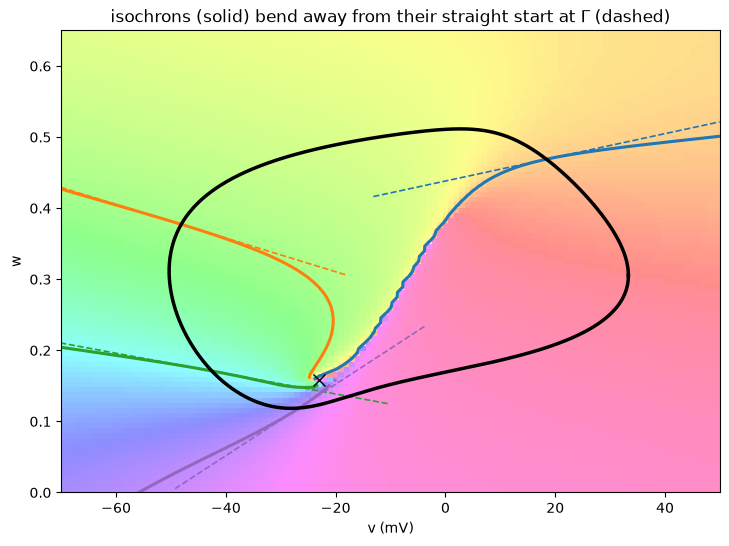

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 6))
phase_background(ax)
for lv, col in ((0.1, "C0"), (0.3, "C1"), (0.5, "C2"), (0.75, "C4")):
    isochron(ax, lv, colors=col, linewidths=2.2)
    g, step = gamma(lv), isochron_step(lv)
    s = np.array([-0.4, 0.4])
    ax.plot(g[0] + step[0] * s, g[1] + step[1] * s, "--", color=col, lw=1.2)
draw_cycle(ax)
ax.set_title("isochrons (solid) bend away from their straight start at Γ (dashed)")
plt.show()

### 0c.2 Folding around the equilibrium

Every isochron must end at x*, the state with no clock reading. Near an unstable spiral the
isochrons wind around it, so all phases meet in any small neighbourhood of x*. Zoom in:

fine map near x*:   0%|          | 0/11 [00:00<?, ?it/s]

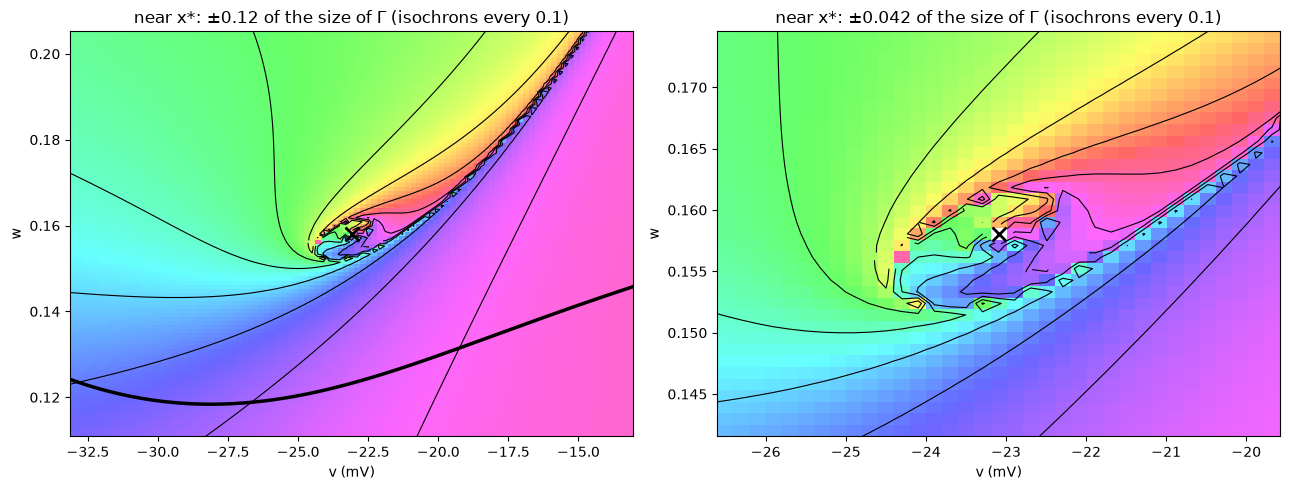

every colour, i.e. every phase, comes into any small window around x*


In [19]:
if xstar is None:
    print("no equilibrium found inside Γ for this oscillator")
else:
    # the main phase map is too coarse here: a fine one around x*, computed once and stored
    LOCAL = MAPFILE.with_name(MAPFILE.stem + "_near_xstar.npz")
    f = 0.12
    if LOCAL.exists():
        dl = np.load(LOCAL); LV, LW, LT = dl["V"], dl["W"], dl["TH"]
    else:
        LV, LW = np.meshgrid(np.linspace(xstar[0] - f * SX, xstar[0] + f * SX, 101),
                             np.linspace(xstar[1] - f * SY, xstar[1] + f * SY, 101))
        gl = np.c_[LV.ravel(), LW.ravel()]
        LT = np.concatenate([clock_reading(gl[s:s + 1000], periods=12)
                             for s in tqdm(range(0, len(gl), 1000), desc="fine map near x*")]).reshape(LV.shape)
        np.savez(LOCAL, V=LV, W=LW, TH=LT)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
    for ax, zoom in ((a1, 1.0), (a2, 0.35)):
        ax.pcolormesh(LV, LW, LT, cmap="hsv", shading="auto", vmin=0, vmax=1, alpha=0.6)
        for lv in np.arange(0.05, 1, 0.1):
            F = LT if 0.25 <= lv <= 0.75 else (LT + 0.5) % 1
            ax.contour(LV, LW, no_wrap(F), [lv if 0.25 <= lv <= 0.75 else (lv + 0.5) % 1],
                       colors="k", linewidths=0.8)
        ax.plot(CX, CY, color="k", lw=2.5); ax.plot(*xstar, "x", color="k", ms=10, mew=2)
        ax.set(xlim=(xstar[0] - zoom * f * SX, xstar[0] + zoom * f * SX),
               ylim=(xstar[1] - zoom * f * SY, xstar[1] + zoom * f * SY), xlabel=LX, ylabel=LY,
               title=f"near x*: ±{zoom * f:.3g} of the size of Γ (isochrons every 0.1)")
    plt.tight_layout(); plt.show()
    print("every colour, i.e. every phase, comes into any small window around x*")

### 0c.3 Piling up

Sample the clock reading along a horizontal line across the inside of Γ, halfway between x*
and the top of Γ. Where the line crosses a pile-up, the reading runs through a large part of
the cycle over a tiny distance.

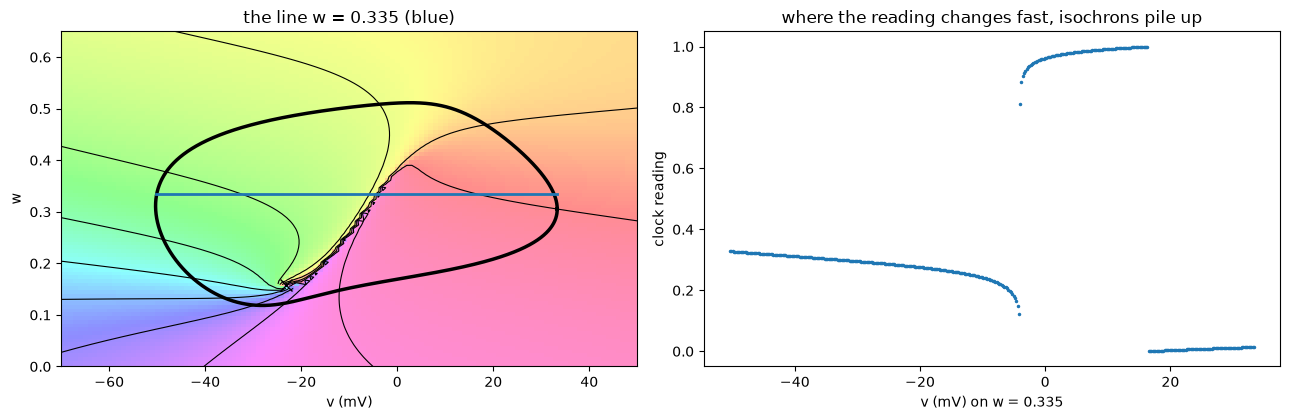

steepest step: 0.311 of a cycle between v = -4.207 and -3.997 (0.21 apart)


In [20]:
yl = (xstar[1] if xstar is not None else CY.mean()) + 0.5 * (CY.max() - (xstar[1] if xstar is not None else CY.mean()))
xl = np.linspace(CX.min(), CX.max(), 400)
thl = clock_reading(np.c_[xl, np.full_like(xl, yl)])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.3))
phase_background(a1)
for lv in np.arange(0, 1, 0.1):
    isochron(a1, lv, colors="k", linewidths=0.8)
draw_cycle(a1); a1.plot(xl, np.full_like(xl, yl), "C0-", lw=2)
a1.set_title(f"the line {Y} = {yl:.3g} (blue)")
a2.plot(xl, thl, ".", ms=3)
a2.set(xlabel=f"{LX} on {Y} = {yl:.3g}", ylabel="clock reading", title="where the reading changes fast, isochrons pile up")
plt.tight_layout(); plt.show()
dth = np.abs(np.diff(np.unwrap(2 * np.pi * np.nan_to_num(thl)) / (2 * np.pi)))
k = int(np.argmax(dth))
print(f"steepest step: {dth[k]:.3f} of a cycle between {X} = {xl[k]:.4g} and {xl[k + 1]:.4g} "
      f"({xl[1] - xl[0]:.3g} apart)")

### 0c.4 A large kick: where it lands decides everything

A kick Δ in the first variable at phase θ moves the state from γ(θ) to γ(θ) + (Δ, 0). Its new
clock reading is that of the isochron it lands on. A small kick lands among straight
isochrons and follows the infinitesimal PRC; a large kick lands among bent, folded or piled-up
ones.

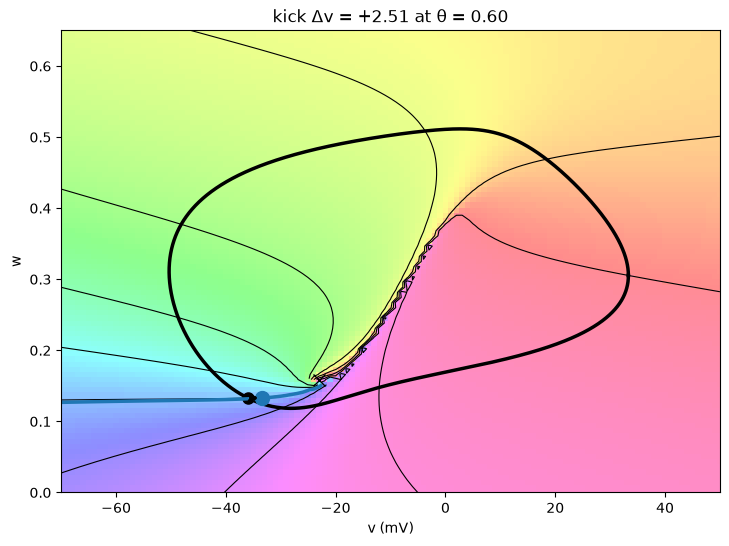

clock reading before 0.6000, after 0.6042: shift +0.0042 cycles (advance); the infinitesimal PRC predicts +0.0027


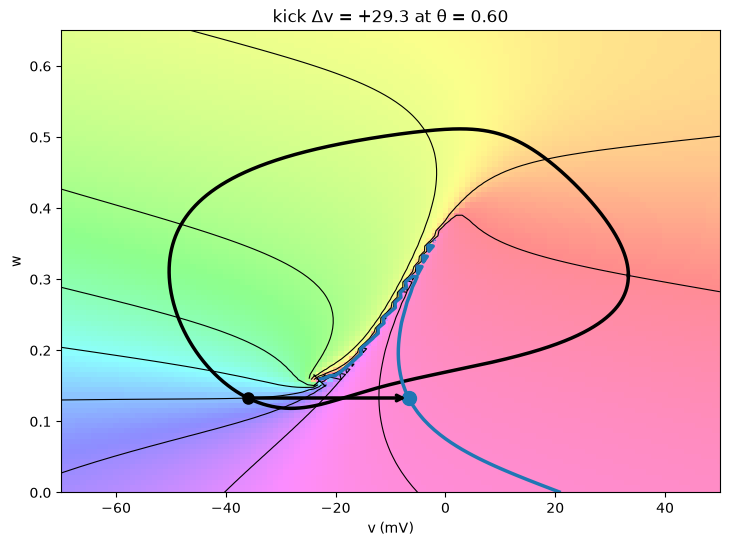

clock reading before 0.6000, after 0.9149: shift +0.3149 cycles (advance); the infinitesimal PRC predicts +0.0309


In [21]:
def show_kick(theta, dk):
    g = gamma(theta)
    kicked = g + np.array([dk, 0.0])
    th_new = clock_reading(kicked)[0]
    fig, ax = plt.subplots(figsize=(8.5, 6))
    phase_background(ax)
    for lv in np.arange(0, 1, 0.1):
        isochron(ax, lv, colors="k", linewidths=0.8)
    draw_cycle(ax)
    ax.annotate("", kicked, g, arrowprops=dict(arrowstyle="->", lw=2.5, color="k"))
    ax.plot(*g, "o", color="k", ms=8); ax.plot(*kicked, "o", color="C0", ms=10)
    if not np.isnan(th_new):
        isochron(ax, th_new, colors="C0", linewidths=2.5)
    ax.set_title(f"kick Δ{X} = {dk:+.3g} at θ = {theta:.2f}")
    plt.show()
    if np.isnan(th_new):
        print("the kicked state has no clock reading yet (it landed next to x*)")
        return
    sh = (th_new - theta + 0.5) % 1 - 0.5
    print(f"clock reading before {theta:.4f}, after {th_new:.4f}: shift {sh:+.4f} cycles "
          f"({'advance' if sh > 0 else 'delay'}); the infinitesimal PRC predicts {Z(theta)[0] * dk / T:+.4f}")


show_kick(0.6, 0.03 * SX)
show_kick(0.6, 0.35 * SX)

**Try it:** choose the phase and the kick, press *Compute*.

In [22]:
c_theta = W.FloatSlider(value=0.45, min=0, max=0.999, step=0.01, description="θ", continuous_update=False)
c_kick = W.FloatSlider(value=float(0.25 * SX), min=float(-0.5 * SX), max=float(0.5 * SX), step=float(SX / 200),
                     description=f"Δ{X}", continuous_update=False, readout_format=".3g")
c_go = W.Button(description="Compute", button_style="primary", icon="play")
c_out = W.Output()
def _c_kick(*_):
    with c_out:
        c_out.clear_output(wait=True); show_kick(c_theta.value, c_kick.value)
c_go.on_click(_c_kick)
display(W.VBox([W.HBox([c_theta, c_kick, c_go]), c_out]))

### 0c.5 PRCs for growing kicks

The phase shift against the phase at which the kick arrives, for kicks from 1 % to 40 % of
the width of Γ, each divided by the kick so that the infinitesimal PRC Z_x/T is the common
limit. Small kicks follow it; large kicks do not, and the PRC jumps where kicks start to land
across a pile-up.

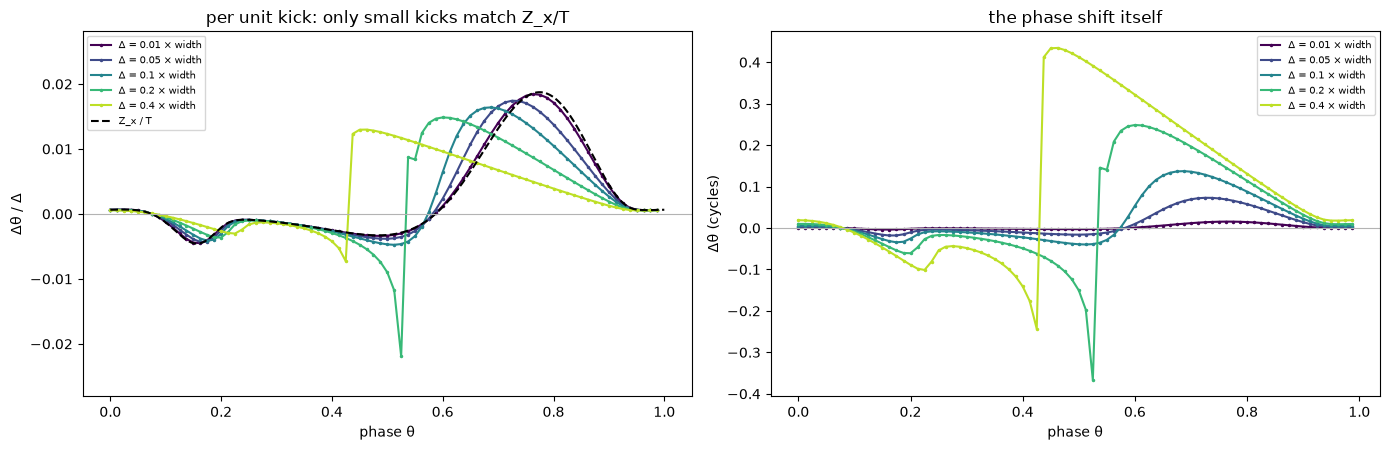

In [23]:
ths = np.linspace(0, 1, 80, endpoint=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6))
for f, col in zip((0.01, 0.05, 0.1, 0.2, 0.4), plt.cm.viridis(np.linspace(0, 0.9, 5))):
    dk = f * SX
    new = clock_reading([gamma(t) + np.array([dk, 0.0]) for t in ths])
    sh = (new - ths + 0.5) % 1 - 0.5
    a1.plot(ths, sh / dk, ".-", color=col, ms=3, label=f"Δ = {f:g} × width")
    a2.plot(ths, sh, ".-", color=col, ms=3, label=f"Δ = {f:g} × width")
a1.plot(ZT / T, ZX / T, "k--", lw=1.5, label="Z_x / T")
lim = 1.5 * np.abs(ZX / T).max()
a1.set(xlabel="phase θ", ylabel="Δθ / Δ", title="per unit kick: only small kicks match Z_x/T", ylim=(-lim, lim))
a2.set(xlabel="phase θ", ylabel="Δθ (cycles)", title="the phase shift itself")
for ax in (a1, a2):
    ax.axhline(0, color="0.7", lw=0.8); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 0c: summary

* Far from Γ the isochrons **bend** away from their straight start, **fold** around the
  equilibrium (every phase meets near x*), and **pile up** where the clock reading changes
  through a large part of the cycle over a tiny distance.
* A **large kick** lands among them: its phase shift is read from the isochron it lands on,
  not from the infinitesimal PRC, and the PRC jumps where kicks start crossing a pile-up.

**Next, stage 01:** the same ideas in detail for FitzHugh–Nagumo and the reduced
Hodgkin–Huxley neuron, where the pile-up becomes too thin for any grid.